# **Section 6: K-Nearest Neighbors**

In this notebook, I will train and evaluate K-Nearest Neighbors (KNN) models. I will start by training a model with a default number of neighbors (k=5), and will then tune the number of neighbors using a cross-validated grid search.

#### **Contents**
1. **Import data**
2. **Basic K-Nearest neighbour model**
    - 2.1 Training and fitting the model
    - 2.2 Evaluating the model
    - 2.3 Classification report and confusion matrix
3. **Hyperparameter optimization**
   - 3.1 Grid search
   - 3.2 Visualizing training / validation curves
4. **Best model evaluation**
   - 4.1. Test set accuracy
   - 4.2 Classification report and confusion matrix
   - 4.3 ROC curve and AUC score
5. **Biomarker identification**
6. **Saving model results**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import warnings
warnings.filterwarnings('ignore')
sns.set_palette("pastel")

## **1. Import data**
Let's load the training and test sets, and their corresponding resistance profiles.

In [2]:
# Load features and labels
sv_train = pd.read_csv("Data/sv_train_selected.csv", index_col=0)
sv_test = pd.read_csv("Data/sv_test_selected.csv", index_col=0)
profiles_train = pd.read_csv("Data/SXT_train_selected.csv", index_col=0)
profiles_test = pd.read_csv("Data/SXT_test_selected.csv", index_col=0)

X_train = sv_train.values
y_train = profiles_train.values.ravel()

X_test = sv_test.values
y_test = profiles_test.values.ravel()

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"Categories: {np.unique(y_train)}")

Training set shape: (177, 199)
Test set shape: (50, 199)
Categories: [0 1]


## **2. Basic K-Nearest Neighbors model**

### **2.1 Training and fitting the model**
Let's start with a baseline KNN model using default parameters (k=5).

In [3]:
# Create KNN pipeline with standardization
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train the model
knn.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,199
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


### **2.2 Evaluating the model**

In [4]:
# Evaluate on training and test sets
accuracy_train = knn.score(X_train, y_train)
accuracy_test = knn.score(X_test, y_test)

print(f"Accuracy training set: {accuracy_train:.4f}")
print(f"Accuracy test set: {accuracy_test:.4f}")

Accuracy training set: 0.8588
Accuracy test set: 0.4800


### **2.3 Classification report and confusion matrix**

In [5]:
# Get predictions
y_test_pred = knn.predict(X_test)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_test_pred))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.13      0.24        30
           1       0.43      1.00      0.61        20

    accuracy                           0.48        50
   macro avg       0.72      0.57      0.42        50
weighted avg       0.77      0.48      0.38        50



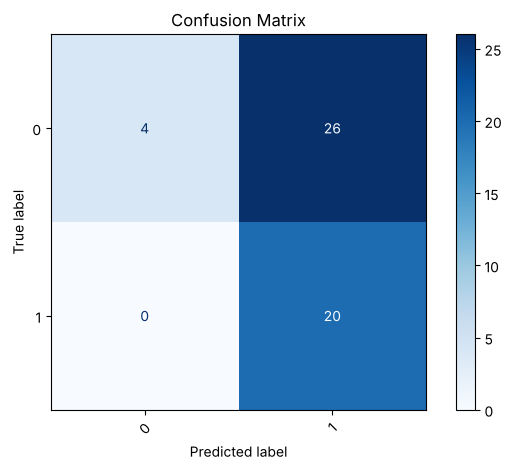

In [6]:
# Confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=knn.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn.classes_)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## **3. Hyperparameter tuning: optimizing k**

Now let's use cross-validated grid search to find the optimal number of neighbors.

### **3.1 Grid Search**

In [7]:
# Create KNN pipeline
knn_pipeline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

# Define parameter grid
param_grid = {'kneighborsclassifier__n_neighbors': [1, 5, 10, 15, 20, 25, 30, 35, 40]}

# Create grid search object
grid_search = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=5,
    return_train_score=True,
    n_jobs=-1
)

# Perform grid search
grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.4f}")

Best parameters: {'kneighborsclassifier__n_neighbors': 10}
Best cross-validation score: 0.7289


In [8]:
cv_results = pd.DataFrame(grid_search.cv_results_)

print(cv_results.loc[:,['mean_test_score', 'std_test_score',
    'mean_train_score', 'std_train_score',
    'param_kneighborsclassifier__n_neighbors'
]].head())

   mean_test_score  std_test_score  mean_train_score  std_train_score  \
0         0.672063        0.082420          1.000000         0.000000   
1         0.717778        0.060985          0.862991         0.016554   
2         0.728889        0.021145          0.789551         0.022086   
3         0.700476        0.039157          0.710468         0.023499   
4         0.694762        0.034344          0.707632         0.023046   

   param_kneighborsclassifier__n_neighbors  
0                                        1  
1                                        5  
2                                       10  
3                                       15  
4                                       20  


### **3.2 Visualize Training/Validation curves**

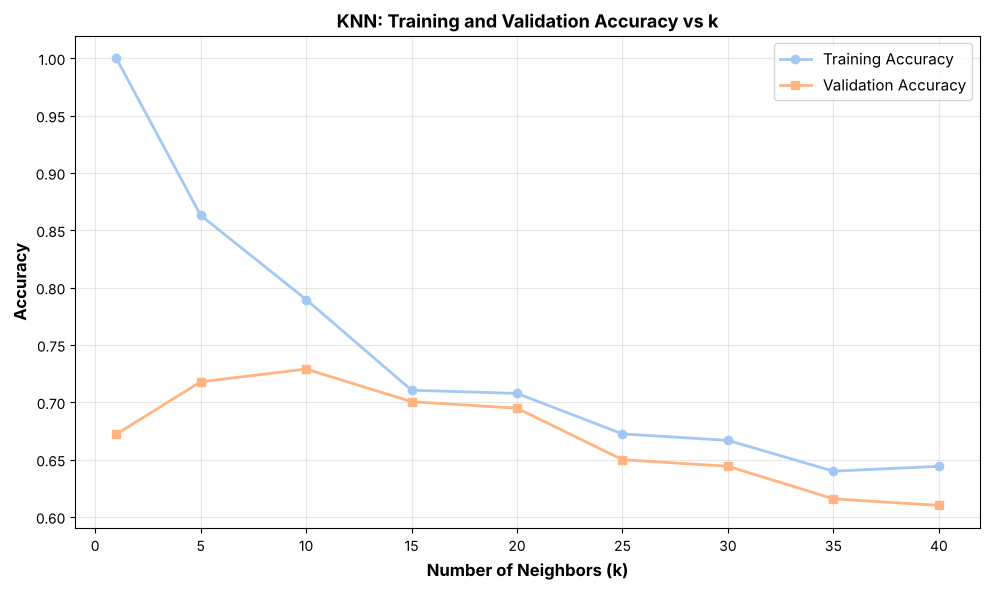

In [9]:
# Sort results by k value for plotting
cv_results_sorted = cv_results.sort_values('param_kneighborsclassifier__n_neighbors')

# Plot accuracy curves
plt.figure(figsize=(10, 6))
plt.plot(
    cv_results_sorted['param_kneighborsclassifier__n_neighbors'],
    cv_results_sorted['mean_train_score'],
    label='Training Accuracy',
    marker='o',
    linewidth=2
)
plt.plot(
    cv_results_sorted['param_kneighborsclassifier__n_neighbors'],
    cv_results_sorted['mean_test_score'],
    label='Validation Accuracy',
    marker='s',
    linewidth=2
)

plt.xlabel('Number of Neighbors (k)', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy', fontsize=12, fontweight='bold')
plt.title('KNN: Training and Validation Accuracy vs k', fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/06_knn_training_curve.png", dpi=300)
plt.show()

If the model performs best with a very low number of neighbours, it simply copies the label of the most similar strain(s). This could mean that the model is learning "lineages" rather than "resistance", which the test set (strains from other lineages) will show.

## **4. Evaluate Best Model**

### **4.1 Test set accuracy**

In [10]:
# Evaluate best model on test set
best_knn = grid_search.best_estimator_
accuracy_test_best = best_knn.score(X_test, y_test)

print(f"\nBest model test accuracy: {accuracy_test_best:.4f}")
print(f"Best k value: {grid_search.best_params_['kneighborsclassifier__n_neighbors']}")


Best model test accuracy: 0.4800
Best k value: 10


### **4.2 Classification report and confusion matrix**

In [11]:
# Get predictions
y_test_pred_best = best_knn.predict(X_test)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_best))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.13      0.24        30
           1       0.43      1.00      0.61        20

    accuracy                           0.48        50
   macro avg       0.72      0.57      0.42        50
weighted avg       0.77      0.48      0.38        50



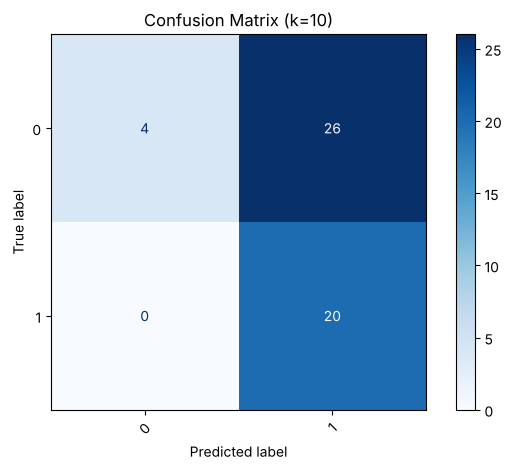

In [12]:
# Confusion matrix
cm_best = confusion_matrix(y_test, y_test_pred_best, labels=best_knn.classes_)
disp_best = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=best_knn.classes_)
disp_best.plot(cmap="Blues", xticks_rotation=45)
plt.title(f"Confusion Matrix (k={grid_search.best_params_['kneighborsclassifier__n_neighbors']})")
plt.tight_layout()
plt.savefig("Figures/06_knn_cm.png", dpi=300)
plt.show()

### **4.3 ROC Curve and AUC score**

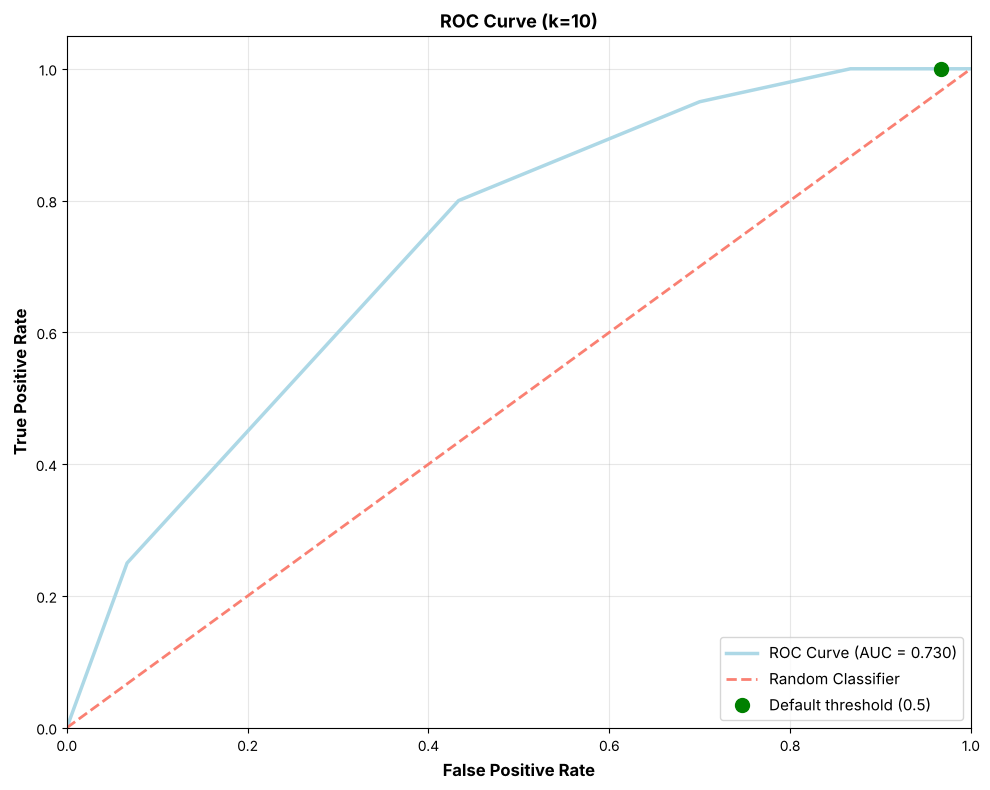


AUC Score: 0.7300
At default threshold (0.5):
True Positive Rate: 1.000 (detects 100.0% of resistants)
False Positive Rate: 0.967 (96.7% of susceptibles are misclassified)


In [13]:
from sklearn.metrics import roc_curve, auc, roc_auc_score

# Get probability predictions for the positive class
y_test_proba = best_knn.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='lightblue', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='salmon', lw=2, linestyle='--', label='Random Classifier')

# Mark 0.5 threshold
default_idx = np.argmin(np.abs(thresholds - 0.5))
plt.plot(fpr[default_idx], tpr[default_idx], 'go', markersize=10, label='Default threshold (0.5)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
plt.title(f'ROC Curve (k={grid_search.best_params_["kneighborsclassifier__n_neighbors"]})', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Figures/06_knn_ROC.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAUC Score: {roc_auc:.4f}")
print(f"At default threshold (0.5):")
print(f"True Positive Rate: {tpr[default_idx]:.3f} (detects {tpr[default_idx]*100:.1f}% of resistants)")
print(f"False Positive Rate: {fpr[default_idx]:.3f} ({fpr[default_idx]*100:.1f}% of susceptibles are misclassified)")

## **5. Biomarker Identification**
Let's now have a look at which features contribute the most to the model.
We will identify biomarkers (features that contribute the most to the model) using **permutation importance**. This method measures how much a model's performance decreases when you randomly shuffle the values for a single feature. If there is a big drop in performance, it means that this feature is important for the model.

### **5.1 Load feature names**
We now don't have access directly to the original features, as they were grouped into clusters in the third notebook. We do however have the cluster numbers (the column names of the feature matrix), and a list of the SVs in each cluster (with their SV type and length) in the file Data/clusters.csv.

In [14]:
cluster_names = sv_train.columns.astype(int).values
features_to_cluster = pd.read_csv("Data/clusters.csv")
features_to_cluster.head()

,cluster,feature,cluster_size,svtype,svlen
0,0,sv__NZ_CP009157.1_4016031_4016119_INV,1,INV,88
1,1,sv__NZ_CP009157.1_1200812_1200910_DEL,1,DEL,98
2,2,sv__NZ_CP009157.1_729822_729873_INV,1,INV,51
3,3,sv__NZ_CP009156.1_3103819_3103911_INV,1,INV,92
4,4,sv__NZ_CP009156.1_2702723_2702784_INV,1,INV,61


### **5.2 Computing feature importance**
Let's now see which clusters contribute the most to predicting resistance using the best model (using permutation importance on the test set, as for the CNVs).

In [15]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_knn,
    X_test,
    y_test,
    scoring="balanced_accuracy",
    n_repeats=15,
    random_state=6,
    n_jobs=-1
)

In [16]:
# Create dataframe with cluster names and importances
importance_df = pd.DataFrame({
    'cluster': cluster_names,
    'importance_mean': perm.importances_mean,
})
# Sort by importance
importance_df = importance_df.sort_values('importance_mean', ascending=False)

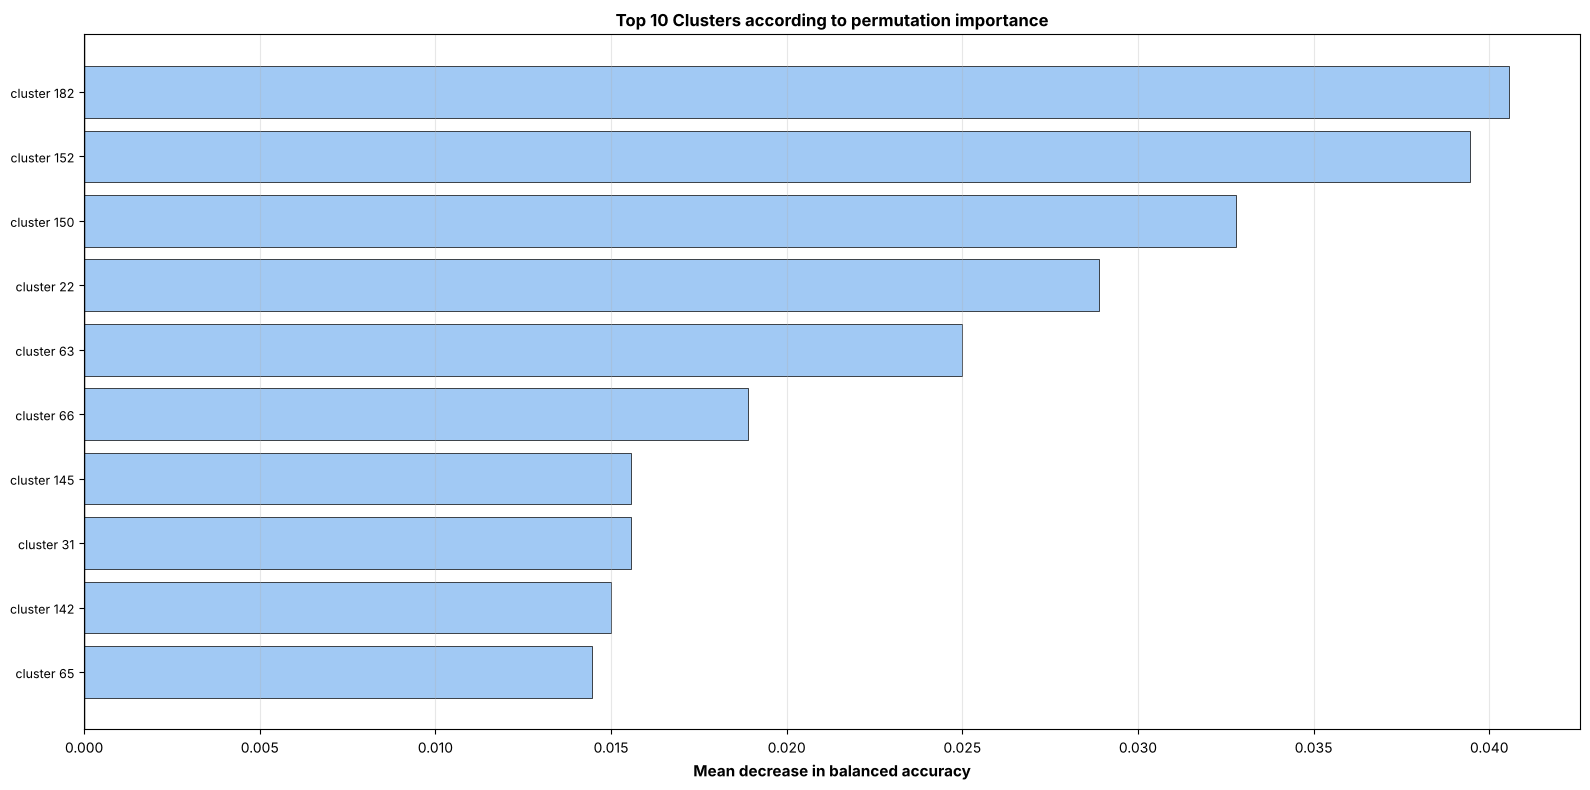

In [17]:
# Visualize top clusters by permutation importance
fig, ax = plt.subplots(1, 1, figsize=(16, 8))

top_features = importance_df.head(10).sort_values("importance_mean")
ax.barh(range(len(top_features)), top_features['importance_mean'], edgecolor='black', linewidth=0.5)
ax.set_yticks(range(len(top_features)))
ax.set_yticklabels([f'cluster {c}' for c in top_features['cluster']], fontsize=9)
ax.set_xlabel('Mean decrease in balanced accuracy', fontweight='bold', fontsize=11)
ax.set_title('Top 10 Clusters according to permutation importance', fontweight='bold', fontsize=12)
ax.axvline(0, color='black', linestyle='-', linewidth=1)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('Figures/06_knn_biomarkers.png', dpi=300, bbox_inches='tight')
plt.show()

In [18]:
print(features_to_cluster[features_to_cluster.cluster.isin(top_features['cluster'])])

     cluster                                feature  cluster_size svtype  \
22        22  sv__NZ_CP009156.1_2098846_2098898_INV             1    INV   
31        31  sv__NZ_CP009157.1_2965216_2965307_INV             1    INV   
63        63  sv__NZ_CP009157.1_4023730_4023825_INV             1    INV   
65        65  sv__NZ_CP009156.1_2163044_2176569_DUP             1    DUP   
66        66  sv__NZ_CP009157.1_2321254_3013198_INV             1    INV   
143      142    sv__NZ_CP009157.1_39705_2935708_INV             1    INV   
146      145  sv__NZ_CP009157.1_3881046_3881956_DUP             1    DUP   
151      150  sv__NZ_CP009156.1_1794244_1794315_DEL             1    DEL   
153      152    sv__NZ_CP009156.1_887713_887764_DEL             1    DEL   
183      182  sv__NZ_CP009157.1_1750018_1750071_DEL             1    DEL   

       svlen  
22        52  
31        91  
63        95  
65     13525  
66    691944  
143  2896003  
146      910  
151       71  
153       51  
183       53 

### **5.3 Save Biomarker results**

In [19]:
# Save biomarker results: the SVs of the top 100 clusters, with the model's score for their cluster
top_clusters = importance_df.head(100)[['cluster', 'importance_mean']]
biomarkers = features_to_cluster.merge(top_clusters, on='cluster')
biomarkers.to_csv("Results/biomarkers_knn.csv", index=False)
print(f"{len(biomarkers)} SVs in the top {len(top_clusters)} clusters saved to Results/biomarkers_knn.csv")

100 SVs in the top 100 clusters saved to Results/biomarkers_knn.csv


## **6. Save Model Results**

In [20]:
import csv
import os

# Store results
results = {
    'model': 'K-Nearest Neighbors',
    'hyperparameters': f"k={grid_search.best_params_['kneighborsclassifier__n_neighbors']}",
    'test_accuracy': float(accuracy_test_best),
    'cv_score': float(grid_search.best_score_)
}

csv_file = "Results/model_results.csv"

# Append results to the csv file
if not os.path.exists(csv_file):
    with open(csv_file, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writeheader()
        writer.writerow(results)
else:
    with open(csv_file, 'a', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=['model', 'hyperparameters', 'test_accuracy', 'cv_score'])
        writer.writerow(results)

print(f"\nResults saved:")
print(f"Model: {results['model']}")
print(f"Hyperparameters: {results['hyperparameters']}")
print(f"Test Accuracy: {results['test_accuracy']:.4f}")
print(f"CV Score: {results['cv_score']:.4f}")


Results saved:
Model: K-Nearest Neighbors
Hyperparameters: k=10
Test Accuracy: 0.4800
CV Score: 0.7289
